$$\textbf{LAPORAN INDIVIDU}$$
$$\textbf{ALJABAR 2}$$
$$\textbf{Analisis Integritas Low-Level NLP pada Ring Polinomial}$$

<center>
  <img src="https://www.its.ac.id/wp-content/uploads/2020/07/Lambang-ITS-2-320x320.png" alt="Logo_ITS" style="width:200px">
</center>

$$\textbf{Disusun Oleh:}$$
<center>
M. Ma'ruf Qomaruddin Kafi - [5002241095]
</center>

$$ $$
$$\textbf{Dosen Pengampu:}$$
<center>
Prof. Dr. Subiono, MS
</center>

$$ $$
$$\textbf{DEPARTEMEN MATEMATIKA}$$
$$\textbf{FAKULTAS SAINS DAN ANALITIKA DATA}$$
$$\textbf{INSTITUT TEKNOLOGI SEPULUH NOPEMBER}$$
$$\textbf{2026}$$

# **1. LATAR BELAKANG DAN LANDASAN TEORI**

# **1.1 LATAR BELAKANG**
> Berbeda dengan model Large Language Model (LLM) modern seperti ChatGPT, Gemini, atau Claude yang berfokus pada **Semantic Similarity** (kedekatan makna melalui vektor embedding desimal), laporan ini berfokus pada **Low-Level NLP**. Di sini, teks tidak dipandang sebagai entitas linguistik yang fleksibel, melainkan sebagai **Vektor Rigid** dalam sebuah struktur aljabar yang kaku.

> Dalam Low-Level NLP, sebuah kalimat dipetakan secara injektif ke dalam **Ring Polinomial** $R[x]$. Tujuan utama sistem ini bukan untuk menyamakan makna (misalnya menganggap "Economy" sama dengan "Finances"), melainkan untuk menjaga integritas barisan karakter (ASCII) sebagai koefisien polinomial.

<center>
<img src="https://labelyourdata.com/cms/wp-content/uploads/2024/10/bg_machine-learning-llm-vs-nlp_6.jpg" width="700">
<p>Gambar 1: Tabel Perbandingan antara Large Language Models (High-Level) dan Natural Language Processing (Low-Level/Tradisional).</p>
</center>

> Pendekatan ini sangat krusial dalam konteks keamanan data dan transmisi informasi. Kita akan mengeksplorasi bagaimana sebuah informasi teks yang "kaku" ini bereaksi terhadap transformasi aljabar: apakah ia tetap stabil dalam **Daerah Integral**, atau mengalami kerusakan informasi (data loss) akibat fenomena pembagi nol pada **Ring Modulo $n$**. Melalui **Lapangan Pecahan**, kita akan membuktikan bahwa data yang telah ditransformasi secara linear hanya dapat dipulihkan secara sempurna jika struktur aljabarnya mendukung eksistensi elemen invers.

> Mengingat cakupan dan batasan pada lingkungan Google Colab, simulasi ini secara spesifik berfokus pada fase **Encoding** (transformasi teks ke polinomial) dan **Decoding** (pemulihan data melalui invers). Laporan ini tidak masuk ke dalam pemrosesan tingkat tinggi (High-Level NLP) yang melibatkan konteks bahasa, melainkan murni membuktikan bahwa stabilitas transmisi data sangat bergantung pada karakteristik matematis dari Ring yang digunakan.

<center>

![Diagram Encoder Decoder](https://miro.medium.com/v2/resize:fit:1100/format:webp/1*aCA6-HH35CY3eYPXXPSHmA.png)

Gambar 2: Arsitektur Dasar Encoder-Decoder yang Diadopsi dalam Simulasi Low-Level NLP.

</center>


# **1.2 LANDASAN TEORI**

### **Ring Polinomial dan Barisan dalam Ring [2.1]**
> Sebuah barisan koefisien $(a_0, a_1, a_2, \dots)$ isomorfik dengan deret formal $A(x) = \sum a_i x^i$. Operasi perkalian pada barisan ini menggunakan **Konvolusi**:
> $$(a * b)_k = \sum_{i+j=k} a_i b_j$$
> Dalam perspektif Low-Level NLP, setiap karakter ASCII adalah titik koordinat unik. Di dalam **Daerah Integral**, identitas vektor ini terjaga karena derajat polinomialnya tetap: $\text{deg}(f \cdot g) = \text{deg}(f) + \text{deg}(g)$. Sebaliknya, pada Ring dengan pembagi nol ($\mathbb{Z}_6$), koordinat vektor ini bisa "lebur" dan hilang, yang secara visual kita kenal sebagai korupsi data.

### **Lapangan Pecahan [2.2]**
> Untuk memulihkan data (dekonvolusi), kita memerlukan semesta yang lebih luas dari sekadar Ring Integritas. Kita memerlukan **Lapangan Pecahan** $F(x)$, di mana setiap filter $K(x)$ memiliki invers $\frac{1}{K(x)}$. Hal ini memungkinkan kita memulihkan barisan teks asli secara presisi, membuktikan bahwa pendekatan aljabar murni mampu menjamin keamanan informasi selama proses transformasi linear berlangsung.

In [ ]:
# import library yang diperlukan
import numpy as np
import matplotlib.pyplot as plt
from sympy import symbols, Poly, ZZ, RR, invert
import pandas as pd
from IPython.display import display, Javascript, Math

print("Library Berhasil Dimuat!")

Library Berhasil Dimuat!


In [ ]:
# @title Input Kalimat (Elemen Barisan Ring)

# Memaksa Google Colab menampilkan seluruh output tanpa scrollbar
display(Javascript('''
  google.colab.output.setIframeHeight(0, true, {maxHeight: 5000});
'''))

kalimat_input = "The global economy shows signs of recovery" # @param {type:"string"}
kalimat_target = "World finances are starting to improve" # @param {type:"string"}

def text_to_coeffs(text):
    # Mengubah karakter menjadi nilai ASCII sebagai koefisien barisan
    return [ord(c) for c in text]

def coeffs_to_text(coeffs):
    # Mengembalikan koefisien ASCII menjadi karakter teks
    return "".join([chr(int(abs(round(c)))) for c in coeffs])

# Jalankan proses konversi
coeffs_p = text_to_coeffs(kalimat_input)
coeffs_target = text_to_coeffs(kalimat_target)

# Judul Cell
print("=== Input Kalimat ===")

# Informasi kata input
print("\n" + "-"*50)
print(f"Kata Input      : '{kalimat_input}'")
print(f"Jumlah Karakter : {len(kalimat_input)} (Maka derajat tertinggi polinomial p(x) adalah {len(kalimat_input) - 1})")

# Menampilkan seluruh karakter ke ASCII
print("\n" + "-"*50)
print("Ubah ke ASCII per karakter:")
for char in kalimat_input:
    display_char = "' '" if char == " " else f"'{char}'"
    print(f"  {display_char} -> {ord(char)}")

print(f"\nBarisan Koefisien p(x) Utuh:\n{coeffs_p}")

# Informasi kata pembanding
print("\n" + "-"*50)
print(f"Kata Pembanding : '{kalimat_target}'")
print(f"Jumlah Karakter : {len(kalimat_target)} (Maka derajat tertinggi polinomial target adalah {len(kalimat_target) - 1})")

# Menampilkan seluruh karakter tanpa potongan
print("\n" + "-"*50)
print("Ubah ke ASCII per karakter:")
for char in kalimat_target:
    display_char = "' '" if char == " " else f"'{char}'"
    print(f"  {display_char} -> {ord(char)}")

print(f"\nBarisan Koefisien Target Utuh:\n{coeffs_target}")

<IPython.core.display.Javascript object>

=== Input Kalimat ===

--------------------------------------------------
Kata Input      : 'The global economy shows signs of recovery'
Jumlah Karakter : 42 (Maka derajat tertinggi polinomial p(x) adalah 41)

--------------------------------------------------
Ubah ke ASCII per karakter:
  'T' -> 84
  'h' -> 104
  'e' -> 101
  ' ' -> 32
  'g' -> 103
  'l' -> 108
  'o' -> 111
  'b' -> 98
  'a' -> 97
  'l' -> 108
  ' ' -> 32
  'e' -> 101
  'c' -> 99
  'o' -> 111
  'n' -> 110
  'o' -> 111
  'm' -> 109
  'y' -> 121
  ' ' -> 32
  's' -> 115
  'h' -> 104
  'o' -> 111
  'w' -> 119
  's' -> 115
  ' ' -> 32
  's' -> 115
  'i' -> 105
  'g' -> 103
  'n' -> 110
  's' -> 115
  ' ' -> 32
  'o' -> 111
  'f' -> 102
  ' ' -> 32
  'r' -> 114
  'e' -> 101
  'c' -> 99
  'o' -> 111
  'v' -> 118
  'e' -> 101
  'r' -> 114
  'y' -> 121

Barisan Koefisien p(x) Utuh:
[84, 104, 101, 32, 103, 108, 111, 98, 97, 108, 32, 101, 99, 111, 110, 111, 109, 121, 32, 115, 104, 111, 119, 115, 32, 115, 105, 103, 110, 115, 32,

In [ ]:
# @title Simulasi Filtering pada Ring Polinomial
from sympy import symbols, Poly, ZZ
from IPython.display import display, Math

x = symbols('x')
p_x = Poly(coeffs_p, x, domain=ZZ)

# Kernel filter: k(x) = 1x + 1 -> k_coeffs = [1, 1]
k_coeffs = [1, 1]
k_x = Poly(k_coeffs, x, domain=ZZ)

# Operasi Konvolusi (Perkalian Polinomial di Daerah Integral ZZ)
res_ideal = p_x * k_x

# Judul Cell
print("=== Simulasi Filtering ===")

# Analisis Struktur
print("\n" + "-"*50)
print("Analisis Struktur di Daerah Integral Z[x]")
print(f"Polinomial Input p(x)  : Berderajat {p_x.degree()} (Terbentuk dari {len(coeffs_p)} Karakter ASCII)")
print(f"Polinomial Kernel k(x) : Berderajat {k_x.degree()} (Menggunakan kernel x + 1)")
print(f"Derajat Hasil Akhir    : {res_ideal.degree()}")

# Verifikasi Derajat
print("\n" + "-"*50)
print("Verifikasi Teorema Derajat")
print(f"deg(p(x)k(x)) = deg(p(x)) + deg(k(x))")
print(f"{res_ideal.degree()}            = {p_x.degree()} + {k_x.degree()}")
print("Terbukti Sesuai Hukum Daerah Integral!")

# Representasi 5 Suku Tertinggi
print("\n" + "-"*50)
print("Representasi Matematis (5 Suku Tertinggi Hasil Konvolusi Ideal):")
suku_tertinggi = res_ideal.all_coeffs()[:5]
deg_max = res_ideal.degree()

math_expr = ""
for i, coeff in enumerate(suku_tertinggi):
    pangkat = deg_max - i
    sign = " + " if i > 0 else ""
    math_expr += rf"{sign}{coeff}x^{{{pangkat}}}"
math_expr += r" + \dots"

display(Math(math_expr))

=== Simulasi Filtering ===

--------------------------------------------------
Analisis Struktur di Daerah Integral Z[x]
Polinomial Input p(x)  : Berderajat 41 (Terbentuk dari 42 Karakter ASCII)
Polinomial Kernel k(x) : Berderajat 1 (Menggunakan kernel x + 1)
Derajat Hasil Akhir    : 42

--------------------------------------------------
Verifikasi Teorema Derajat
deg(p(x)k(x)) = deg(p(x)) + deg(k(x))
42            = 41 + 1
Terbukti Sesuai Hukum Daerah Integral!

--------------------------------------------------
Representasi Matematis (5 Suku Tertinggi Hasil Konvolusi Ideal):


<IPython.core.display.Math object>

In [ ]:
# @title Eksperimen Pembagi Nol (Ring Modulo n)
import math
from sympy import Poly, ZZ
from sympy.abc import x
from IPython.display import display, Math

n_val = 12 # @param [2, 3, 4, 5, 6, 12] {type:"raw"}

try:
    # Definisikan koefisien input
    coeffs_int = [int(c) for c in coeffs_p]

    # Definisikan kernel k(x) = 3x + 2
    k_coeffs = [3, 2]

    # Perkalian polinomial di Ring ZZ (Karakteristik 0 / Kondisi Ideal)
    p_x_zz = Poly(coeffs_int, x, domain=ZZ)
    k_x_zz = Poly(k_coeffs, x, domain=ZZ)
    res_poly_zz = p_x_zz * k_x_zz

    # Pindah ke Ring Zn via operasi Modulo
    raw_coeffs = res_poly_zz.all_coeffs()
    mod_coeffs = [int(c % n_val) for c in raw_coeffs]

    # Buat polinomial baru dari hasil modulo untuk mengecek derajat akhir
    # Perlu membuang angka 0 di depan agar derajatnya dihitung akurat oleh SymPy
    while len(mod_coeffs) > 0 and mod_coeffs[0] == 0:
        mod_coeffs.pop(0)

    if len(mod_coeffs) == 0:
        res_glitch = Poly([0], x, domain=ZZ)
    else:
        res_glitch = Poly(mod_coeffs, x, domain=ZZ)

    # Judul Cell
    print("=== Eksperimen Pembagi Nol ===")

    # Simulasi Penurunan Derajat
    print("\n" + "-"*50)
    print(f"Simulasi Penurunan Derajat")
    print(f"Derajat Polinomial Input p(x)  : {p_x_zz.degree()}")
    print(f"Derajat Polinomial Kernel k(x) : {k_x_zz.degree()}")
    print(f"Derajat Seharusnya (Ideal)     : {p_x_zz.degree() + k_x_zz.degree()}")
    print(f"Derajat Akhir Nyata (Z_{n_val})    : {res_glitch.degree()}")

    # Cari daftar pembagi nol di Z_n secara matematis untuk edukasi
    zero_divisors = [i for i in range(1, n_val) if math.gcd(i, n_val) != 1]

    # Cek apakah terjadi fenomena hilangnya suku tertinggi
    ideal_deg = p_x_zz.degree() + k_x_zz.degree()
    real_deg = res_glitch.degree()

    if real_deg < ideal_deg:
        print("\n" + "-"*50)
        print(f"[!] HASIL ANALISIS (Penurunan Derajat Terdeteksi):")
        print(f"Terjadi penurunan derajat dari {ideal_deg} menjadi {real_deg}!")
        print(f"Suku tertinggi awal p(x)*k(x) bernilai {raw_coeffs[0]}x^{{{ideal_deg}}}")
        print(f"Saat direduksi ke Z_{n_val}: {raw_coeffs[0]} mod {n_val} = 0")
        print(f"Akibat koefisien bernilai 0, suku x^{{{ideal_deg}}} (dan mungkin di bawahnya) LENYAP dari polinomial.")
        print("\n" + "-"*50)
        print(f"[Materi Aljabar]:")
        print(f"Hal ini membuktikan secara empiris bahwa Z_{n_val} BUKAN Daerah Integral.")
        print(f"Daftar elemen Pembagi Nol (Zero Divisors) di Z_{n_val} adalah: {zero_divisors}")
        print(f"Karena koefisien {raw_coeffs[0]} bersekutu dengan pembagi nol di Z_{n_val}, integritas data teks hancur.")
    else:
        print("\n" + "-"*50)
        print(f"[!] HASIL ANALISIS (Derajat Stabil):")
        print(f"Derajat tetap stabil di angka {real_deg}.")
        print(f"Koefisien tertinggi {raw_coeffs[0]} mod {n_val} = {raw_coeffs[0] % n_val} (tidak menjadi 0).")
        print(f"Struktur Z_{n_val} pada kasus input ini tidak memicu pemusnahan suku tertinggi.")
        if len(zero_divisors) == 0:
            print(f"Catatan: Z_{n_val} adalah LAPANGAN (Field) karena {n_val} bilangan prima, sehingga tidak memiliki pembagi nol.")
        else:
            print(f"Catatan: Meskipun derajat stabil, Z_{n_val} tetap memiliki pembagi nol: {zero_divisors}. Coba ganti kalimat atau n_val.")

except Exception as e:
    print(f"Error dalam simulasi Ring: {e}")

=== Eksperimen Pembagi Nol ===

--------------------------------------------------
Simulasi Penurunan Derajat
Derajat Polinomial Input p(x)  : 41
Derajat Polinomial Kernel k(x) : 1
Derajat Seharusnya (Ideal)     : 42
Derajat Akhir Nyata (Z_12)    : 40

--------------------------------------------------
[!] HASIL ANALISIS (Penurunan Derajat Terdeteksi):
Terjadi penurunan derajat dari 42 menjadi 40!
Suku tertinggi awal p(x)*k(x) bernilai 252x^{42}
Saat direduksi ke Z_12: 252 mod 12 = 0
Akibat koefisien bernilai 0, suku x^{42} (dan mungkin di bawahnya) LENYAP dari polinomial.

--------------------------------------------------
[Materi Aljabar]:
Hal ini membuktikan secara empiris bahwa Z_12 BUKAN Daerah Integral.
Daftar elemen Pembagi Nol (Zero Divisors) di Z_12 adalah: [2, 3, 4, 6, 8, 9, 10]
Karena koefisien 252 bersekutu dengan pembagi nol di Z_12, integritas data teks hancur.


=== Visualisasi Perbandingan Derajat Ideal vs Modulo ===



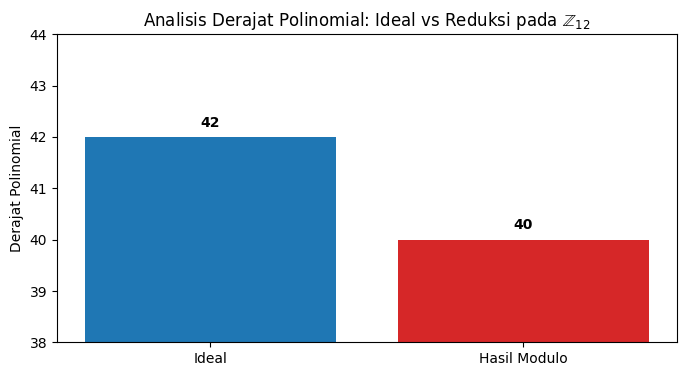


--------------------------------------------------
Analisis Visual
Ideal             : Derajat polinomial tanpa gangguan pembagi nol.
Hasil Modulo      : Derajat setelah operasi reduksi ke Z_12. (Jika < Ideal, terjadi Degree Drop).
Penurunan Derajat : Sebesar 2 tingkat. TERJADI PENURUNAN!


In [ ]:
# @title Visualisasi Perbandingan Derajat (Ideal vs Modulo)

# Siapkan data untuk plot
derajat = [ideal_deg, real_deg]
labels = ['Ideal', 'Hasil Modulo']

# Atur ukuran plot
plt.figure(figsize=(8, 4))

# Buat bar chart. Biru = Ideal/stabil, Merah = Hasil modulo/berisiko drop
plt.bar(labels, derajat, color=['#1f77b4', '#d62728'])

# Judul Cell
print("=== Visualisasi Perbandingan Derajat Ideal vs Modulo ===\n")

# Memberikan label sumbu dan judul
plt.ylabel('Derajat Polinomial')
plt.title(rf'Analisis Derajat Polinomial: Ideal vs Reduksi pada $\mathbb{{Z}}_{{{n_val}}}$')
plt.ylim(min(derajat) - 2, max(derajat) + 2)

# Menampilkan teks angka tepat di atas bar
for i, v in enumerate(derajat):
    plt.text(i, v + 0.2, str(v), ha='center', fontweight='bold')

plt.show()

# Penjelasan Output
print("\n" + "-"*50)
print("Analisis Visual")
print("Ideal             : Derajat polinomial tanpa gangguan pembagi nol.")
print("Hasil Modulo      : Derajat setelah operasi reduksi ke Z_{}. (Jika < Ideal, terjadi Degree Drop).".format(n_val))
print(f"Penurunan Derajat : Sebesar {ideal_deg - real_deg} tingkat. " + ("TERJADI PENURUNAN!" if ideal_deg > real_deg else "TIDAK TERJADI PENURUNAN."))

In [ ]:
# @title Pemulihan Data via Invers Polinomial (Lapangan Pecahan)

try:
    # Definisikan koefisien
    signal_coeffs = [float(c) for c in res_poly_zz.all_coeffs()]
    filter_coeffs = [float(c) for c in k_x_zz.all_coeffs()]

    # Operasi Dekonvolusi (Pembagian Polinomial / Aplikasi Perkalian Invers 1/K(x))
    recovered_coeffs, remainder = np.polydiv(signal_coeffs, filter_coeffs)

    # Konversi Kembali ke ASCII
    teks_pulih = coeffs_to_text(recovered_coeffs)
    sum_remainder = np.sum(np.abs(remainder))


    # Judul Cell
    print("=== Pemulihan Data via Invers Polinomial ===")

    # Simulasi Pemulihan
    print("\n" + "-"*50)
    print("Proses Pemulihan Pada Lapangan Pecahan F(x)")
    print(f"Teks Input Asli     : '{kalimat_input}'")
    print(f"Teks Hasil Invers   : '{teks_pulih}'")
    print(f"Sisa Pembagian      : {sum_remainder}")

    print("\n" + "-"*50)
    print("Analisis Integritas Data")
    if sum_remainder < 1e-5:
        print("STATUS: RECOVERY SUKSES (Integritas 100%)")
        print(f"Sisa pembagian 0 membuktikan operasi pembagian eksak di Lapangan Pecahan.")
        print(f"Data berhasil dipulihkan total tanpa ada karakter yang cacat.")
    else:
        print("STATUS: RECOVERY GAGAL (Data Corrupted)")
        print(f"Sisa pembagian tidak bernilai 0. Terjadi distorsi koefisien.")

    # Perbandingan dengan teks pembanding
    print("\n" + "-"*50)
    print(f"Verifikasi Akhir dengan Teks Pembanding")
    print(f"Teks Hasil Pulih : '{teks_pulih.strip()}'")
    print(f"Teks Pembanding  : '{kalimat_target.strip()}'")

    # Verifikasi Rigid Berbasis Operator Relasional
    print("\n" + "-"*50)
    if teks_pulih.strip() == kalimat_target.strip():
        print("STATUS    : [TEXT INPUT SAMA DENGAN TEKS PEMBANDING]")
        print("Kesimpulan: Teks pulih sama persis dengan teks pembanding.")
    else:
        print("STATUS    : [TEXT INPUT TIDAK SAMA DENGAN TEKS PEMBANDING]")
        print("Analisis  : Hasil pulih TIDAK SAMA dengan kalimat pembanding.")
        print("Ini membuktikan sistem Low-Level NLP bekerja secara kaku (rigid/exact match),")
        print("bukan mencari kedekatan makna (semantic similarity) seperti High-Level NLP.")

except Exception as e:
    print(f"Error dalam proses pemulihan: {e}")

=== Pemulihan Data via Invers Polinomial ===

--------------------------------------------------
Proses Pemulihan Pada Lapangan Pecahan F(x)
Teks Input Asli     : 'The global economy shows signs of recovery'
Teks Hasil Invers   : 'The global economy shows signs of recovery'
Sisa Pembagian      : 0.0

--------------------------------------------------
Analisis Integritas Data
STATUS: RECOVERY SUKSES (Integritas 100%)
Sisa pembagian 0 membuktikan operasi pembagian eksak di Lapangan Pecahan.
Data berhasil dipulihkan total tanpa ada karakter yang cacat.

--------------------------------------------------
Verifikasi Akhir dengan Teks Pembanding
Teks Hasil Pulih : 'The global economy shows signs of recovery'
Teks Pembanding  : 'World finances are starting to improve'

--------------------------------------------------
STATUS    : [TEXT INPUT TIDAK SAMA DENGAN TEKS PEMBANDING]
Analisis  : Hasil pulih TIDAK SAMA dengan kalimat pembanding.
Ini membuktikan sistem Low-Level NLP bekerja secara kak

# **KESIMPULAN, ANALISIS AKHIR & CATATAN**

Berdasarkan eksplorasi matematis pada struktur **Ring Polinomial dan Barisan**, dapat ditarik beberapa poin analisis utama:

## **1. Isomorfisma Struktur Data**
Implementasi ini membuktikan adanya isomorfisma antara struktur barisan teks dan Ring Polinomial $R[x]$. Melalui pemetaan injektif, operasi konvolusi pada barisan teks bersesuaian secara struktur atau sering disebut *structure-preserving* dengan operasi perkalian polinomial, yang menunjukkan bahwa teks dapat dimanipulasi sepenuhnya sebagai objek aljabar. Adapun proses pemetaan (mapping) karakter menjadi nilai ASCII merupakan fondasi krusial dalam implementasi ini, di mana setiap karakter bertindak sebagai koefisien yang menentukan koordinat dan identitas unik dari polinomial tersebut.

## **2. Karakteristik Ring dan Integritas**
Eksperimen pada **Ring Modulo $n$** (misal pada $\mathbb{Z}_{12}$) menunjukkan bahwa keberadaan **Pembagi Nol** (Zero Divisors) adalah ancaman nyata bagi integritas data. Ketika koefisien tertinggi dari hasil konvolusi teks dan kernel menghasilkan nilai yang kongruen dengan 0 (seperti kasus $252 \pmod{12} = 0$), terjadi fenomena *Degree Drop* (penurunan derajat). Hal ini bermanifestasi sebagai hilangnya informasi karakter secara permanen dari alamat memori komputer.

## **3. Kekuatan Lapangan Pecahan**
Pemulihan data (dekonvolusi murni) terbukti hanya dapat dilakukan secara stabil jika kita memperluas semesta pembicaraan ke **Lapangan Pecahan**. Sifat lapangan yang menjamin eksistensi elemen invers ($\frac{1}{K(x)}$ untuk setiap filter $K(x) \neq 0$) memungkinkan kita melakukan operasi pembagian polinomial untuk mendapatkan kembali barisan data asli secara presisi tanpa menyisakan karakter atau dengan hasil pembagian atau *remainder* = 0.0. Keberhasilan decoding bergantung sepenuhnya pada eksistensi elemen invers. Dalam struktur Lapangan, operasi pembagian polinomial menjadi eksak dan terdefinisi dengan baik yang menjamin integritas barisan data asli.

## **4. Relevansi pada Software Engineering**
Pemahaman terhadap Daerah Integral dan Lapangan Pecahan merupakan fondasi utama dalam merancang sistem komunikasi data, kriptografi, maupun algoritma deteksi eror (*Error Correction Code*) yang tahan terhadap *noise* atau *data corruption* akibat limitasi karakteristik mesin (*finite precision*).

## **5. Evaluasi Pemilihan Struktur Modulo**
Melalui logika *else-condition* pada simulasi, dibuktikan bahwa memilih parameter $n$ yang salah pada Ring $\mathbb{Z}_n$ akan langsung merusak struktur data. Namun, meskipun derajat polinomialnya tetap stabil (cocok), integritas isinya belum tentu sempurna karena sifat pemetaan modulo yang bersifat *many-to-one* berisiko menimbulkan ambiguitas karakter (*glitch*) saat didekode kembali. Oleh karena itu, jika ingin diimplementasikan pada data teks digital, disarankan menggunakan $\mathbb{Z}_n$ di mana $n$ adalah bilangan prima (sehingga strukturnya menjadi Lapangan) atau beralih murni ke Lapangan Pecahan.

## **6. Batasan Representasi Aljabar (Low-Level vs High-Level NLP)**
Perlu digarisbawahi bahwa simulasi pada lingkungan Google Colab ini murni merupakan bentuk **Low-Level NLP** yang berfokus pada fase *Encoding* (transformasi teks rigid ke polinomial) dan *Decoding* (pemulihan data melalui invers). Sistem ini tidak melibatkan pemrosesan tingkat tinggi (*High-Level NLP*) yang menangkap konteks bahasa atau kedekatan makna (*Semantic Similarity*). Penggunaan operator relasional `==` pada verifikasi akhir membuktikan bahwa sistem ini tidak mentoleransi distorsi karakter sekecil apa pun, karena dalam struktur Ring perubahan satu koefisien akan menghasilkan elemen yang sepenuhnya berbeda atau sering disebut sifat *deterministik-rigid* (sangat sensitif terhadap perubahan karakter), bukan probabilitas-semantik seperti pada arsitektur LLM modern (ChatGPT, Gemini, Claude). Adapun *Low-Level NLP* adalah proses yang sangat krusial apabila ingin berkecimpung di dunia *High-Level NLP*, maka dari itu penting untuk mengetahui apa yang terjadi di balik sistem tersebut.